<a href="https://colab.research.google.com/github/miriamamin1213-ux/Ablation_studies/blob/main/HancockGPT2CN3Fold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
# HANCOCK GPT-2 CLASSIFIER
# ============================================================
# 1. IMPORT LIBRARIES, SET SEEDS AND SELECT DEVICE
# ============================================================
import os, random, json, gdown
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    roc_curve, precision_recall_curve
)

SEED = 42

def seed_everything(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND MERGE HANCOCK CLINICAL/PATHOLOGICAL DATA
# ============================================================
CLINICAL_FILE = "clinical_data.json"
PATHOLOGICAL_FILE = "pathological_data.json"

if not os.path.exists(CLINICAL_FILE):
    if gdown.download(
        id="1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q",
        output=CLINICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download clinical_data.json.")

if not os.path.exists(PATHOLOGICAL_FILE):
    if gdown.download(
        id="1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F",
        output=PATHOLOGICAL_FILE, quiet=False
    ) is None:
        raise FileNotFoundError("Could not download pathological_data.json.")

def load_json_table(path):
    with open(path, "r", encoding="utf-8") as f:
        obj = json.load(f)
    if isinstance(obj, list):
        return pd.DataFrame(obj)
    if isinstance(obj, dict):
        for key in ["data", "records", "patients", "items"]:
            if key in obj and isinstance(obj[key], list):
                return pd.DataFrame(obj[key])
        try:
            return pd.DataFrame(obj)
        except ValueError:
            pass
    raise ValueError(f"Could not convert {path} to a table.")

clinical_df = load_json_table(CLINICAL_FILE)
pathological_df = load_json_table(PATHOLOGICAL_FILE)
if ("patient_id" not in clinical_df.columns or
        "patient_id" not in pathological_df.columns):
    raise KeyError("Both JSON files must contain 'patient_id'.")

df = clinical_df.merge(
    pathological_df, on="patient_id", how="left",
    suffixes=("", "_path")
)
print("Clinical shape:", clinical_df.shape)
print("Pathology shape:", pathological_df.shape)
print("Merged shape:", df.shape)

# ============================================================
# 3. SELECT SIX FEATURES AND DEFINE THE HPV TARGET
# ============================================================
def resolve_col(candidates, required=False):
    for c in candidates:
        if c in df.columns:
            return c
    if required:
        raise KeyError(
            f"Required column not found: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )
    return None

target_col = resolve_col(
    ["hpv_association_p16", "hpv_association_p16_path"],
    required=True
)
feature_candidates = {
    "age_at_initial_diagnosis": [
        "age_at_initial_diagnosis", "age_at_initial_diagnosis_path"
    ],
    "sex": ["sex", "sex_path"],
    "smoking_status": ["smoking_status", "smoking_status_path"],
    "primary_tumor_site": [
        "primary_tumor_site", "primary_tumor_site_path"
    ],
    "primarily_metastasis": [
        "primarily_metastasis", "primarily_metastasis_path"
    ],
    "pN_stage": [
        "pN_stage", "pN_stage_path",
        "pathological_N_stage", "pathological_n_stage"
    ]
}
feature_map = {
    name: resolve_col(cols, required=True)
    for name, cols in feature_candidates.items()
}
features = list(feature_candidates.keys())
df = df.dropna(subset=[target_col]).copy()

def normalize_target(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    if s in ["negative", "neg", "0", "false", "no"]:
        return 0
    if s in ["positive", "pos", "1", "true", "yes"]:
        return 1
    try:
        n = float(s)
        if n in [0, 1]:
            return int(n)
    except ValueError:
        pass
    return np.nan

df["HPV_Label"] = df[target_col].apply(normalize_target)
df = df.dropna(subset=["HPV_Label"]).copy()
df["HPV_Label"] = df["HPV_Label"].astype(int)
feature_df = df[[feature_map[c] for c in features]].copy()
feature_df = feature_df.rename(
    columns={feature_map[c]: c for c in features}
)
df = pd.concat([feature_df, df[["HPV_Label"]]], axis=1)
df = df.loc[:, ~df.columns.duplicated()].copy()
df["age_at_initial_diagnosis"] = pd.to_numeric(
    df["age_at_initial_diagnosis"], errors="coerce"
)
print("Patients:", len(df))
print("HPV classes (0=negative, 1=positive):")
print(df["HPV_Label"].value_counts().sort_index())
print("Features:", features)
print("N-stage source:", feature_map["pN_stage"])

# ============================================================
# 4. STRATIFIED TRAIN/VALIDATION/TEST SPLIT (65/15/20)
# ============================================================
train_val_df, test_df = train_test_split(
    df, test_size=0.20, random_state=SEED,
    stratify=df["HPV_Label"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV_Label"]
)
train_df, val_df, test_df = (
    split.copy() for split in [train_df, val_df, test_df]
)

# ============================================================
# 5. IMPUTE MISSING VALUES USING TRAINING DATA ONLY
# ============================================================
fill_values = {}
for c in features:
    if pd.api.types.is_numeric_dtype(train_df[c]):
        value = train_df[c].median()
        if pd.isna(value):
            value = 0
    else:
        modes = train_df[c].dropna().astype(str).mode()
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[c] = value
    for split in [train_df, val_df, test_df]:
        split[c] = split[c].fillna(value)
        if split[c].dtype == object:
            split[c] = split[c].astype(str).replace({
                "": "Unknown", "nan": "Unknown", "None": "Unknown"
            })

y_train = train_df["HPV_Label"].to_numpy(dtype=int)
y_val = val_df["HPV_Label"].to_numpy(dtype=int)
y_test = test_df["HPV_Label"].to_numpy(dtype=int)
print("Train:", len(train_df), np.bincount(y_train, minlength=2))
print("Validation:", len(val_df), np.bincount(y_val, minlength=2))
print("Test:", len(test_df), np.bincount(y_test, minlength=2))

# ============================================================
# 6. CONVERT SIX FEATURES INTO CLINICAL TEXT PROMPTS
# ============================================================
def display_value(x):
    if pd.isna(x):
        return "Unknown"
    if isinstance(x, (float, np.floating)) and float(x).is_integer():
        return str(int(x))
    return str(x).strip()

def patient_to_text(row):
    parts = [
        "Q: Predict this patient's Human Papillomavirus (HPV) "
        "status using the clinical information available."
    ]
    labels = {
        "age_at_initial_diagnosis": "Age at initial diagnosis",
        "sex": "Sex",
        "smoking_status": "Smoking status",
        "primary_tumor_site": "Primary tumour site",
        "primarily_metastasis": "Primarily metastasis",
        "pN_stage": "Pathological N stage"
    }
    for c in features:
        parts.append(f"{labels[c]}: {display_value(row[c])}.")
    parts.append(
        "Is this patient HPV positive? "
        "Answer with only Yes or No.\nA:"
    )
    return " ".join(parts)

train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]
print("Example prompt:\n", train_texts[0], "\nTarget label:", y_train[0])

# ============================================================
# 7. LOAD TOKENIZER AND SELECT MAXIMUM LENGTH
# ============================================================
MODEL_NAME = "openai-community/gpt2"
tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Determine the length policy from training prompts only to avoid
# using validation/test data to choose preprocessing parameters.
TRAIN_PROMPT_LENGTHS = [
    len(tokenizer.encode(t, add_special_tokens=False))
    for t in train_texts
]
print("Training prompt tokens: min =", min(TRAIN_PROMPT_LENGTHS),
      "| median =", int(np.median(TRAIN_PROMPT_LENGTHS)),
      "| 95th percentile =", int(np.percentile(TRAIN_PROMPT_LENGTHS, 95)),
      "| max =", max(TRAIN_PROMPT_LENGTHS))
MAX_LENGTH = min(
    1024, max(32, int(np.ceil(max(TRAIN_PROMPT_LENGTHS) / 8) * 8))
)
if max(TRAIN_PROMPT_LENGTHS) > 1024:
    print("WARNING: Some training prompts exceed GPT-2's context limit.")
print("Selected MAX_LENGTH:", MAX_LENGTH)

BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DROPOUT = 0.1
print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS,
      "| Learning rate:", LEARNING_RATE,
      "| Weight decay:", WEIGHT_DECAY)

# ============================================================
# 8. BUILD DATASETS AND DATA LOADERS
# ============================================================
class HPVTextDataset(Dataset):
    def __init__(self, texts, labels):
        self.items = []
        for text, label in zip(texts, labels):
            encoded = tokenizer(
                text, max_length=MAX_LENGTH, padding="max_length",
                truncation=True, return_tensors="pt"
            )
            self.items.append((
                encoded["input_ids"].squeeze(0),
                encoded["attention_mask"].squeeze(0), int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        input_ids, attention_mask, label = self.items[index]
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "label": torch.tensor(label, dtype=torch.long)
        }

train_dataset = HPVTextDataset(train_texts, y_train)
val_dataset = HPVTextDataset(val_texts, y_val)
test_dataset = HPVTextDataset(test_texts, y_test)
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    generator=train_generator, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)


# ============================================================
# 9. INITIALISE FROZEN GPT-2 CLASSIFIER AND CLASS WEIGHTS
# ============================================================

class HPVNetGPT2Text(nn.Module):
    def __init__(self, model_name=MODEL_NAME, num_classes=2,
                 dropout=DROPOUT):
        super().__init__()

        # Load GPT-2 backbone
        self.gpt2 = GPT2Model.from_pretrained(model_name)

        # FREEZE ALL GPT-2 PARAMETERS
        for param in self.gpt2.parameters():
            param.requires_grad = False

        self.gpt2.config.use_cache = False
        self.gpt2.config.pad_token_id = tokenizer.pad_token_id

        hidden_size = self.gpt2.config.hidden_size

        # CLASSIFIER HEAD REMAINS TRAINABLE
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, 128),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask,
            use_cache=False,
            return_dict=True
        )

        hidden_states = outputs.last_hidden_state

        # Pool the final non-padding token
        last_positions = attention_mask.sum(dim=1) - 1

        pooled_output = hidden_states[
            torch.arange(hidden_states.size(0), device=hidden_states.device),
            last_positions
        ]

        return self.classifier(pooled_output)


# Initialise model
model = HPVNetGPT2Text().to(device)

# Verify trainable parameters
gpt2_trainable = sum(
    p.numel() for p in model.gpt2.parameters() if p.requires_grad
)

classifier_trainable = sum(
    p.numel() for p in model.classifier.parameters() if p.requires_grad
)

print("GPT-2 trainable parameters:", gpt2_trainable)
print("Classifier trainable parameters:", classifier_trainable)
print("Total trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

# Class weights
class_counts = np.bincount(y_train, minlength=2)

class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32,
    device=device
)

print("Class weights [negative, positive]:",
      class_weights.detach().cpu().numpy())

# Loss function
def weighted_classification_loss(logits, labels):
    losses = nn.functional.cross_entropy(
        logits, labels, reduction="none"
    )
    return (losses * class_weights[labels]).mean()

# Optimise ONLY the classifier head
optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ============================================================
# 10. HPV SCORES, VALIDATION LOSS AND THRESHOLD SELECTION
# ============================================================
def get_hpv_scores(loader):
    model.eval()
    scores, labels_all = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            scores.extend(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            labels_all.extend(batch["label"].numpy())
    return np.asarray(scores, dtype=float), np.asarray(labels_all, dtype=int)

def evaluate_loss(loader):
    model.eval()
    total_loss, total_examples = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)
            logits = model(input_ids=input_ids,
                           attention_mask=attention_mask)
            loss = weighted_classification_loss(logits, labels)
            n = labels.size(0)
            total_loss += loss.item() * n
            total_examples += n
    return total_loss / max(total_examples, 1)

def select_threshold(scores, labels):
    thresholds = np.unique(np.concatenate(([0.0], scores, [1.0])))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    # Maximise balanced accuracy; ties go to the threshold closest to 0.5.
    return max(results, key=lambda x: (x[1], -abs(x[0] - 0.5)))

# ============================================================
# 11. TRAIN AND SAVE BEST VALIDATION CHECKPOINTS
# ============================================================
OUT_DIR = Path("ROC_HANCOCK_GPT2_CLASSIFIER")
OUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_paths = {
    "Validation_Loss": OUT_DIR / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": OUT_DIR / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": OUT_DIR / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy":
        OUT_DIR / "best_model_validation_balanced_accuracy.pth"
}
best = {
    "Validation_Loss": {
        "value": float("inf"), "epoch": None, "threshold": None
    },
    "Validation_ROC_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_PR_AUC": {
        "value": -float("inf"), "epoch": None, "threshold": None
    },
    "Validation_Balanced_Accuracy": {
        "value": -float("inf"), "epoch": None, "threshold": None
    }
}
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.gpt2.eval()
    train_loss_sum, train_examples = 0.0, 0
    for batch in train_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=input_ids, attention_mask=attention_mask)
        loss = weighted_classification_loss(logits, labels)
        loss.backward()
        optimizer.step()
        n = labels.size(0)
        train_loss_sum += loss.item() * n
        train_examples += n

    train_loss = train_loss_sum / max(train_examples, 1)
    val_loss = evaluate_loss(val_loader)
    val_scores, val_labels = get_hpv_scores(val_loader)
    val_auc = roc_auc_score(val_labels, val_scores)
    val_ap = average_precision_score(val_labels, val_scores)
    val_threshold, val_ba = select_threshold(val_scores, val_labels)
    history.append({
        "Epoch": epoch, "Train_Loss": train_loss,
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })
    metrics = {
        "Validation_Loss": val_loss, "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba
    }
    for metric, value in metrics.items():
        improved = (
            value < best[metric]["value"] if metric == "Validation_Loss"
            else value > best[metric]["value"]
        )
        if improved:
            best[metric] = {
                "value": float(value), "epoch": epoch,
                "threshold": float(val_threshold)
            }
            torch.save(model.state_dict(), checkpoint_paths[metric])

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Threshold={val_threshold:.6f}"
        )

pd.DataFrame(history).to_csv(OUT_DIR / "training_history.csv", index=False)
best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric, "Best_Epoch": info["epoch"],
        "Best_Validation_Metric": info["value"],
        "Threshold_Selected_On_Validation": info["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, info in best.items()
])
best_summary.to_csv(
    OUT_DIR / "best_validation_checkpoints.csv", index=False
)
print("\nBEST VALIDATION CHECKPOINTS\n", best_summary.to_string(index=False))

# ============================================================
# 12. EVALUATE CHECKPOINTS ON THE HELD-OUT TEST SET
# ============================================================
test_results, test_predictions = [], {}
for metric, path in checkpoint_paths.items():
    print(f"\n===== CHECKPOINT: {metric} =====")
    model.load_state_dict(torch.load(path, map_location=device))
    scores, labels = get_hpv_scores(test_loader)
    threshold = best[metric]["threshold"]
    predictions = (scores >= threshold).astype(int)
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    ba = balanced_accuracy_score(labels, predictions)
    f1 = f1_score(labels, predictions, zero_division=0)
    cm = confusion_matrix(labels, predictions, labels=[0, 1])
    print("Best epoch:", best[metric]["epoch"])
    print(f"Validation threshold: {threshold:.6f}")
    print(classification_report(
        labels, predictions, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(
        f"Test ROC-AUC: {auc:.4f} | Test PR-AUC (AP): {ap:.4f} | "
        f"Test Balanced Accuracy: {ba:.4f} | F1: {f1:.4f}"
    )
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", cm)
    test_results.append({
        "Dataset": "HANCOCK", "Model": "GPT-2 Classifier",
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": auc, "Test_PR_AUC_Average_Precision": ap,
        "Test_Balanced_Accuracy": ba, "Test_F1": f1,
        "TN": int(cm[0, 0]), "FP": int(cm[0, 1]),
        "FN": int(cm[1, 0]), "TP": int(cm[1, 1])
    })
    test_predictions[metric] = {
        "scores": scores, "predictions": predictions,
        "labels": labels, "threshold": threshold
    }
    pd.DataFrame({
        "True_Label": labels, "HPV_Positive_Score": scores,
        "Predicted_Label": predictions, "Threshold": threshold
    }).to_csv(OUT_DIR / f"test_predictions_{metric.lower()}.csv", index=False)

results_df = pd.DataFrame(test_results)
results_df.to_csv(OUT_DIR / "test_metrics_by_checkpoint.csv", index=False)
print("\nTEST RESULTS BY CHECKPOINT\n", results_df.to_string(index=False))

# ============================================================
# 13. SAVE ROC AND PRECISION-RECALL CURVES FOR ALL CHECKPOINTS
# ============================================================
for metric, result in test_predictions.items():
    labels, scores = result["labels"], result["scores"]
    auc = roc_auc_score(labels, scores)
    ap = average_precision_score(labels, scores)
    fpr, tpr, roc_thresholds = roc_curve(labels, scores)
    precision, recall, _ = precision_recall_curve(labels, scores)
    safe_name = metric.lower()
    pd.DataFrame({
        "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
    }).to_csv(OUT_DIR / f"roc_coordinates_{safe_name}.csv", index=False)
    pd.DataFrame({
        "Precision": precision, "Recall": recall
    }).to_csv(
        OUT_DIR / f"precision_recall_coordinates_{safe_name}.csv",
        index=False
    )
    plt.figure(figsize=(7, 6))
    plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {auc:.4f}")
    plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"HANCOCK GPT-2 Classifier ROC: {metric}")
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"roc_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

    plt.figure(figsize=(7, 6))
    plt.plot(recall, precision, linewidth=2, label=f"PR-AUC (AP) = {ap:.4f}")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"HANCOCK GPT-2 Classifier Precision-Recall: {metric}")
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        OUT_DIR / f"precision_recall_curve_{safe_name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.close()

# ============================================================
# 14. SAVE SETTINGS AND APPEND RESULTS TO COMPARISON CSV
# ============================================================
settings = {
    "Dataset": "HANCOCK", "Model": MODEL_NAME,
    "Model_Type": "GPT-2 Classifier",
    "Features": ", ".join(features), "Number_of_Features": len(features),
    "Target": target_col, "Positive_Class": 1,
    "Positive_Class_Name": "HPV Positive",
    "Learning_Rate": LEARNING_RATE, "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW", "Epochs": EPOCHS, "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Max_Length_Method": (
        "Training prompts only; rounded to multiple of 8; capped at 1024"
    ),
    "Random_Seed": SEED, "Train_Validation_Test_Split": "65/15/20 stratified",
    "SMOTE": False, "Gradient_Clipping": False,
    "GPT2_Backbone_Frozen": True, "Dropout": DROPOUT,
    "Class_Weights": str(class_weights.detach().cpu().numpy().tolist()),
    "Checkpoint_Selection": (
        "Best validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "Threshold_Selection": (
        "Maximise validation balanced accuracy; ties closest to 0.5"
    ),
    "HPV_Positive_Score": "Softmax probability for class 1 (HPV positive)",
    "Curves": (
        "Test ROC and precision-recall curves saved for each checkpoint"
    )
}
pd.DataFrame([settings]).to_csv(OUT_DIR / "settings.csv", index=False)

comparison_file = Path("model_roc_pr_auc_comparison.csv")
comparison_rows = results_df[[
    "Dataset", "Model", "Checkpoint_Selected_By", "Best_Epoch",
    "Test_ROC_AUC", "Test_PR_AUC_Average_Precision",
    "Test_Balanced_Accuracy", "Test_F1"
]].rename(columns={"Test_PR_AUC_Average_Precision": "Test_PR_AUC"})

if comparison_file.exists():
    existing = pd.read_csv(comparison_file)
    for col in comparison_rows.columns:
        if col not in existing.columns:
            existing[col] = np.nan
    for col in existing.columns:
        if col not in comparison_rows.columns:
            comparison_rows[col] = np.nan
    combined = pd.concat(
        [existing, comparison_rows[existing.columns]], ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"], keep="last"
    )
else:
    combined = comparison_rows

combined.to_csv(comparison_file, index=False)
print("\nSaved classifier outputs to:", OUT_DIR.resolve())
print("AUC comparison file:", comparison_file.resolve())

Device: cuda


Downloading...
From: https://drive.google.com/uc?id=1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q
To: /content/clinical_data.json
100%|██████████| 810k/810k [00:00<00:00, 85.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F
To: /content/pathological_data.json
100%|██████████| 458k/458k [00:00<00:00, 195MB/s]


Clinical shape: (763, 32)
Pathology shape: (763, 18)
Merged shape: (763, 49)
Patients: 332
HPV classes (0=negative, 1=positive):
HPV_Label
0    191
1    141
Name: count, dtype: int64
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis', 'pN_stage']
N-stage source: pN_stage
Train: 215 [123  92]
Validation: 50 [29 21]
Test: 67 [39 28]
Example prompt:
 Q: Predict this patient's Human Papillomavirus (HPV) status using the clinical information available. Age at initial diagnosis: 53. Sex: male. Smoking status: smoker. Primary tumour site: Oropharynx. Primarily metastasis: no. Pathological N stage: pN0. Is this patient HPV positive? Answer with only Yes or No.
A: 
Target label: 0


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Total trainable parameters: 100226
Class weights [negative, positive]: [0.87398374 1.1684783 ]
Epoch 50/500 | Train Loss=0.6972 | Val Loss=0.6911 | Val ROC-AUC=0.7660 | Val PR-AUC=0.7240 | Val BA=0.7455 | Threshold=0.519946
Epoch 100/500 | Train Loss=0.6937 | Val Loss=0.6882 | Val ROC-AUC=0.7545 | Val PR-AUC=0.6943 | Val BA=0.7389 | Threshold=0.507385
Epoch 150/500 | Train Loss=0.6957 | Val Loss=0.6870 | Val ROC-AUC=0.7594 | Val PR-AUC=0.6969 | Val BA=0.7455 | Threshold=0.440753
Epoch 200/500 | Train Loss=0.6781 | Val Loss=0.6733 | Val ROC-AUC=0.7562 | Val PR-AUC=0.7109 | Val BA=0.7455 | Threshold=0.484133
Epoch 250/500 | Train Loss=0.6703 | Val Loss=0.6631 | Val ROC-AUC=0.7594 | Val PR-AUC=0.7065 | Val BA=0.7455 | Threshold=0.494989
Epoch 300/500 | Train Loss=0.6957 | Val Loss=0.6562 | Val ROC-AUC=0.7578 | Val PR-AUC=0.6981 | Val BA=0.7348 | Threshold=0.501725
Epoch 350/500 | Train Loss=0.6405 | Val Loss=0.6469 | Va

In [5]:
from pathlib import Path
import shutil

source = Path("/content/ROC_HANCOCK_GPT2_CLASSIFIER")
destination = Path(
    "/content/drive/MyDrive/HANCOCK_GPT2_Discriminative_Frozen_results"
)

destination.mkdir(parents=True, exist_ok=True)

if not source.exists():
    raise FileNotFoundError(f"Output folder not found: {source}")

for item in source.iterdir():
    target = destination / item.name

    if item.is_dir():
        shutil.copytree(item, target, dirs_exist_ok=True)
    else:
        shutil.copy2(item, target)

print("Files copied to:", destination)
print("\nSaved files:")
for item in sorted(destination.rglob("*")):
    if item.is_file():
        print(item.relative_to(destination))

Files copied to: /content/drive/MyDrive/HANCOCK_GPT2_Discriminative_Frozen_results

Saved files:
best_model_validation_balanced_accuracy.pth
best_model_validation_loss.pth
best_model_validation_pr_auc.pth
best_model_validation_roc_auc.pth
best_validation_checkpoints.csv
precision_recall_coordinates_validation_balanced_accuracy.csv
precision_recall_coordinates_validation_loss.csv
precision_recall_coordinates_validation_pr_auc.csv
precision_recall_coordinates_validation_roc_auc.csv
precision_recall_curve_validation_balanced_accuracy.png
precision_recall_curve_validation_loss.png
precision_recall_curve_validation_pr_auc.png
precision_recall_curve_validation_roc_auc.png
roc_coordinates_validation_balanced_accuracy.csv
roc_coordinates_validation_loss.csv
roc_coordinates_validation_pr_auc.csv
roc_coordinates_validation_roc_auc.csv
roc_curve_validation_balanced_accuracy.png
roc_curve_validation_loss.png
roc_curve_validation_pr_auc.png
roc_curve_validation_roc_auc.png
settings.csv
test_metrics

In [6]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score
)

# --------------------------------------------------
# 1. Locate the epoch-498 test predictions
# --------------------------------------------------
source = Path("/content/ROC_HANCOCK_GPT2_CLASSIFIER")

prediction_file = source / "test_predictions_validation_loss.csv"

if not prediction_file.exists():
    candidates = list(source.rglob("*validation_loss*.csv"))
    candidates = [
        p for p in candidates
        if "prediction" in p.name.lower()
    ]
    if not candidates:
        raise FileNotFoundError(
            "Could not find the Validation Loss test prediction CSV. "
            "Check the files in the output folder."
        )
    prediction_file = candidates[0]

df = pd.read_csv(prediction_file)
print("Using:", prediction_file)
print("Columns:", df.columns.tolist())

# --------------------------------------------------
# 2. Extract labels and predicted probabilities
# --------------------------------------------------
y_true = df["True_Label"].to_numpy().astype(int)
y_score = df["HPV_Positive_Score"].to_numpy().astype(float)

THRESHOLD = 0.396864

y_pred = (y_score >= THRESHOLD).astype(int)

assert len(y_true) == 67, f"Expected 67 test patients, got {len(y_true)}"
assert len(np.unique(y_true)) == 2

# --------------------------------------------------
# 3. Calculate observed test metrics
# --------------------------------------------------
def calculate_metrics(y, scores, threshold):
    pred = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y, pred, labels=[0, 1]
    ).ravel()

    return {
        "ROC_AUC": roc_auc_score(y, scores),
        "PR_AUC": average_precision_score(y, scores),
        "Balanced_Accuracy": balanced_accuracy_score(y, pred),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y, pred, zero_division=0)
    }

observed = calculate_metrics(y_true, y_score, THRESHOLD)

# --------------------------------------------------
# 4. Stratified bootstrap confidence intervals
# --------------------------------------------------
rng = np.random.default_rng(42)
N_BOOTSTRAPS = 5000

negative_indices = np.where(y_true == 0)[0]
positive_indices = np.where(y_true == 1)[0]

bootstrap_results = {key: [] for key in observed}

for _ in range(N_BOOTSTRAPS):
    sampled_negative = rng.choice(
        negative_indices,
        size=len(negative_indices),
        replace=True
    )
    sampled_positive = rng.choice(
        positive_indices,
        size=len(positive_indices),
        replace=True
    )

    indices = np.concatenate([
        sampled_negative,
        sampled_positive
    ])
    rng.shuffle(indices)

    metrics = calculate_metrics(
        y_true[indices],
        y_score[indices],
        THRESHOLD
    )

    for key, value in metrics.items():
        bootstrap_results[key].append(value)

# --------------------------------------------------
# 5. Construct 95% confidence intervals
# --------------------------------------------------
rows = []

for metric, value in observed.items():
    lower, upper = np.percentile(
        bootstrap_results[metric],
        [2.5, 97.5]
    )

    rows.append({
        "Dataset": "HANCOCK",
        "Model": "GPT-2 Clinical Narrative Discriminative (Frozen)",
        "Checkpoint": "Validation_Loss",
        "Best_Epoch": 498,
        "Test_N": len(y_true),
        "Threshold": THRESHOLD,
        "Metric": metric,
        "Estimate": value,
        "CI_95_Lower": lower,
        "CI_95_Upper": upper
    })

ci_df = pd.DataFrame(rows)

# --------------------------------------------------
# 6. Save permanently to Google Drive
# --------------------------------------------------
output_folder = Path(
    "/content/drive/MyDrive/"
    "HANCOCK_GPT2_Discriminative_Frozen_results"
)
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / (
    "HANCOCK_GPT2_Discriminative_Frozen_confidence_intervals.csv"
)

ci_df.to_csv(output_file, index=False)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------
print("\n95% BOOTSTRAP CONFIDENCE INTERVALS")
print("Checkpoint: Validation Loss | Epoch 498")
print("Bootstrap iterations:", N_BOOTSTRAPS)

for _, row in ci_df.iterrows():
    print(
        f"{row['Metric']}: "
        f"{row['Estimate']:.4f} "
        f"(95% CI: {row['CI_95_Lower']:.4f}–"
        f"{row['CI_95_Upper']:.4f})"
    )

print("\nSaved successfully to:")
print(output_file)


Using: /content/ROC_HANCOCK_GPT2_CLASSIFIER/test_predictions_validation_loss.csv
Columns: ['True_Label', 'HPV_Positive_Score', 'Predicted_Label', 'Threshold']

95% BOOTSTRAP CONFIDENCE INTERVALS
Checkpoint: Validation Loss | Epoch 498
Bootstrap iterations: 5000
ROC_AUC: 0.7225 (95% CI: 0.5907–0.8379)
PR_AUC: 0.7009 (95% CI: 0.5816–0.8242)
Balanced_Accuracy: 0.6593 (95% CI: 0.5545–0.7592)
Sensitivity: 0.8571 (95% CI: 0.7143–0.9643)
Specificity: 0.4615 (95% CI: 0.3077–0.6154)
F1: 0.6575 (95% CI: 0.5676–0.7429)

Saved successfully to:
/content/drive/MyDrive/HANCOCK_GPT2_Discriminative_Frozen_results/HANCOCK_GPT2_Discriminative_Frozen_confidence_intervals.csv



HANCOCK — FOLD 1/3
Training patients: 221
Training class counts: [127  94]
Validation patients: 111
Validation class counts: [64 47]
MAX_LENGTH: 88


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


MODEL FREEZING CHECK
GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Total trainable parameters: 100226
VERIFIED: Only the classifier head is trainable.
Class weights: [0.87007874 1.1755319 ]
Fold 1 | Epoch 50/500 | Train Loss=0.6913 | Val Loss=0.6916 | ROC-AUC=0.6980 | PR-AUC=0.6305 | BA=0.6672
Fold 1 | Epoch 100/500 | Train Loss=0.6903 | Val Loss=0.6919 | ROC-AUC=0.7101 | PR-AUC=0.6524 | BA=0.6828
Fold 1 | Epoch 150/500 | Train Loss=0.6893 | Val Loss=0.6867 | ROC-AUC=0.7094 | PR-AUC=0.6480 | BA=0.6729
Fold 1 | Epoch 200/500 | Train Loss=0.6919 | Val Loss=0.6793 | ROC-AUC=0.7098 | PR-AUC=0.6476 | BA=0.6705
Fold 1 | Epoch 250/500 | Train Loss=0.6670 | Val Loss=0.6691 | ROC-AUC=0.7133 | PR-AUC=0.6543 | BA=0.6705
Fold 1 | Epoch 300/500 | Train Loss=0.6531 | Val Loss=0.6568 | ROC-AUC=0.7138 | PR-AUC=0.6533 | BA=0.6656
Fold 1 | Epoch 350/500 | Train Loss=0.6594 | Val Loss=0.6495 | ROC-AUC=0.7174 | PR-AUC=0.6548 | BA=0.6734
Fold 1 | Epoch 400/500 | Train Loss=0.6300 |

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


MODEL FREEZING CHECK
GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Total trainable parameters: 100226
VERIFIED: Only the classifier head is trainable.
Class weights: [0.87007874 1.1755319 ]
Fold 2 | Epoch 50/500 | Train Loss=0.6938 | Val Loss=0.6929 | ROC-AUC=0.6468 | PR-AUC=0.4878 | BA=0.6642
Fold 2 | Epoch 100/500 | Train Loss=0.6918 | Val Loss=0.6933 | ROC-AUC=0.6567 | PR-AUC=0.4940 | BA=0.6684
Fold 2 | Epoch 150/500 | Train Loss=0.6852 | Val Loss=0.6949 | ROC-AUC=0.6584 | PR-AUC=0.4947 | BA=0.6755
Fold 2 | Epoch 200/500 | Train Loss=0.6747 | Val Loss=0.6998 | ROC-AUC=0.6538 | PR-AUC=0.4923 | BA=0.6649
Fold 2 | Epoch 250/500 | Train Loss=0.6714 | Val Loss=0.6947 | ROC-AUC=0.6534 | PR-AUC=0.4921 | BA=0.6642
Fold 2 | Epoch 300/500 | Train Loss=0.6695 | Val Loss=0.6994 | ROC-AUC=0.6488 | PR-AUC=0.4899 | BA=0.6642
Fold 2 | Epoch 350/500 | Train Loss=0.6336 | Val Loss=0.6824 | ROC-AUC=0.6641 | PR-AUC=0.5138 | BA=0.6642
Fold 2 | Epoch 400/500 | Train Loss=0.6458 |

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]


MODEL FREEZING CHECK
GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Total trainable parameters: 100226
VERIFIED: Only the classifier head is trainable.
Class weights: [0.8671875 1.1808511]
Fold 3 | Epoch 50/500 | Train Loss=0.6914 | Val Loss=0.6973 | ROC-AUC=0.6910 | PR-AUC=0.6730 | BA=0.6841
Fold 3 | Epoch 100/500 | Train Loss=0.6891 | Val Loss=0.6996 | ROC-AUC=0.7018 | PR-AUC=0.6935 | BA=0.6918
Fold 3 | Epoch 150/500 | Train Loss=0.6933 | Val Loss=0.6998 | ROC-AUC=0.7075 | PR-AUC=0.7012 | BA=0.6999
Fold 3 | Epoch 200/500 | Train Loss=0.6650 | Val Loss=0.6968 | ROC-AUC=0.7082 | PR-AUC=0.7052 | BA=0.7079
Fold 3 | Epoch 250/500 | Train Loss=0.6749 | Val Loss=0.6921 | ROC-AUC=0.7099 | PR-AUC=0.7098 | BA=0.7079
Fold 3 | Epoch 300/500 | Train Loss=0.6724 | Val Loss=0.6850 | ROC-AUC=0.7096 | PR-AUC=0.7117 | BA=0.6999
Fold 3 | Epoch 350/500 | Train Loss=0.6583 | Val Loss=0.6718 | ROC-AUC=0.7082 | PR-AUC=0.7062 | BA=0.6999
Fold 3 | Epoch 400/500 | Train Loss=0.6534 | V

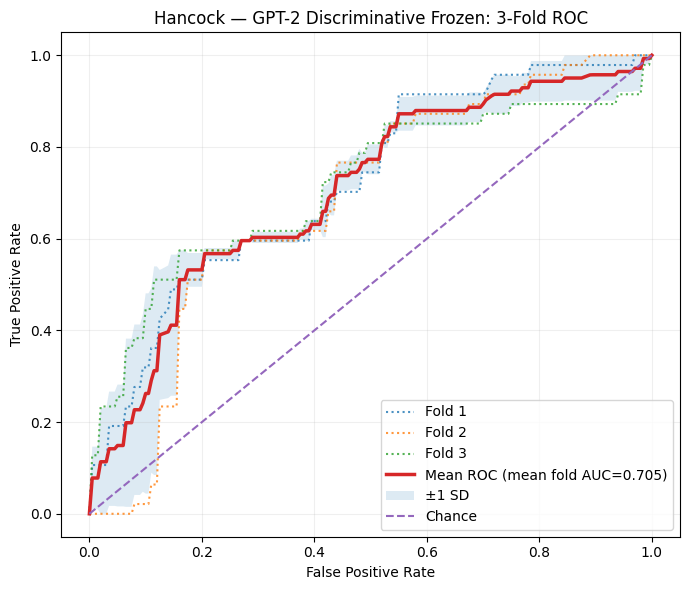

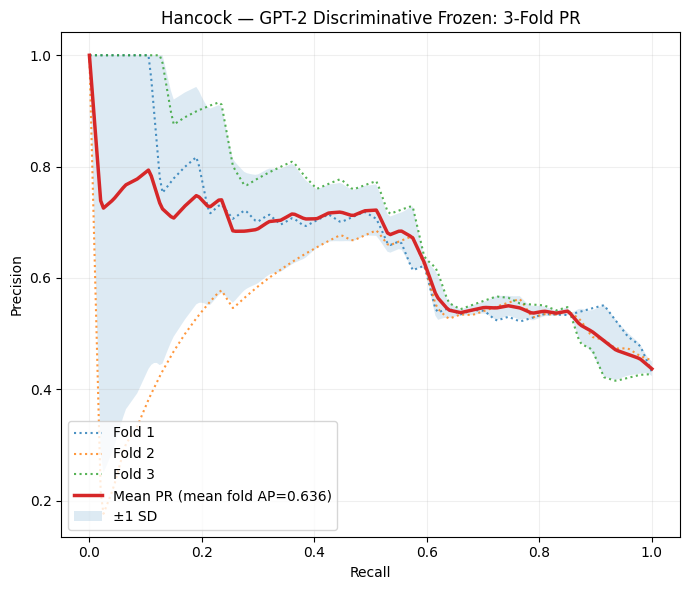


HANCOCK GPT-2 FROZEN STANDARD 3-FOLD CV COMPLETED
Patients used: 332
Features used: 6
GPT-2 trainable parameters: 0
Classifier trainable parameters: 100226
Three folds completed: 3
Output folder: /content/drive/MyDrive/HANCOCK_GPT2_Discriminative_Frozen_3Fold_CV_HECKTOR_STYLE


In [12]:

# ============================================================
# HANCOCK GPT-2 DISCRIMINATIVE — FROZEN BACKBONE
# STANDARD STRATIFIED 3-FOLD CROSS-VALIDATION
# MATCHES THE EARLIER HECKTOR 3-FOLD APPROACH
#
# Each fold:
#   - 2 folds for training
#   - 1 fold for validation
#   - Validation fold selects checkpoint and threshold
#   - Same validation fold provides ROC/PR curves and metrics
#
# No inner validation split. No separate test set.
# ============================================================

# Use a NEW output folder so the previous nested-CV run is preserved.
OUT_DIR = Path(
    "/content/drive/MyDrive/"
    "HANCOCK_GPT2_Discriminative_Frozen_3Fold_CV_HECKTOR_STYLE"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 10. STRATIFIED THREE-FOLD CROSS-VALIDATION
# ============================================================

skf = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=CV_SEED
)

fold_splits = list(
    skf.split(cv_df[FEATURES], cv_df[TARGET])
)

fold_metrics = []
fold_roc_curves = []
fold_pr_curves = []

roc_grid = np.linspace(0, 1, 201)
recall_grid = np.linspace(0, 1, 201)

for fold_number, (train_idx, val_idx) in enumerate(
    fold_splits, start=1
):

    print("\n" + "=" * 70)
    print(f"HANCOCK — FOLD {fold_number}/3")
    print("=" * 70)

    fold_seed = CV_SEED + fold_number
    set_seed(fold_seed)

    # Two folds for training; one fold for validation.
    train_df = cv_df.iloc[train_idx].copy()
    val_df = cv_df.iloc[val_idx].copy()

    # Fit imputation on training fold only.
    # Apply those training-derived values to validation fold.
    train_df, val_df = impute_fold(train_df, val_df)

    y_train = train_df[TARGET].to_numpy(dtype=int)
    y_val = val_df[TARGET].to_numpy(dtype=int)

    print("Training patients:", len(y_train))
    print("Training class counts:", np.bincount(y_train, minlength=2))
    print("Validation patients:", len(y_val))
    print("Validation class counts:", np.bincount(y_val, minlength=2))

    # Clinical narratives using exactly the same six features.
    train_texts = [
        patient_to_text(row)
        for _, row in train_df.iterrows()
    ]

    val_texts = [
        patient_to_text(row)
        for _, row in val_df.iterrows()
    ]

    # Determine sequence length from training prompts only.
    train_lengths = [
        len(tokenizer.encode(text, add_special_tokens=False))
        for text in train_texts
    ]

    max_length = min(
        1024,
        max(32, int(np.ceil(max(train_lengths) / 8) * 8))
    )

    print("MAX_LENGTH:", max_length)

    # Datasets and loaders.
    train_ds = HPVTextDataset(
        train_texts, y_train, max_length
    )

    val_ds = HPVTextDataset(
        val_texts, y_val, max_length
    )

    generator = torch.Generator().manual_seed(fold_seed)

    train_loader = DataLoader(
        train_ds,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    val_loader = DataLoader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )

    # --------------------------------------------------------
    # INITIALISE A FRESH FROZEN GPT-2 MODEL FOR THIS FOLD
    # --------------------------------------------------------

    model = HPVNetGPT2Text().to(device)

    gpt2_trainable = sum(
        p.numel()
        for p in model.gpt2.parameters()
        if p.requires_grad
    )

    classifier_trainable = sum(
        p.numel()
        for p in model.classifier.parameters()
        if p.requires_grad
    )

    total_trainable = sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

    print("\nMODEL FREEZING CHECK")
    print("GPT-2 trainable parameters:", gpt2_trainable)
    print("Classifier trainable parameters:", classifier_trainable)
    print("Total trainable parameters:", total_trainable)

    assert gpt2_trainable == 0, "GPT-2 backbone is not frozen."
    assert classifier_trainable == 100226
    assert total_trainable == 100226

    print("VERIFIED: Only the classifier head is trainable.")

    # --------------------------------------------------------
    # CLASS WEIGHTS FROM TRAINING FOLD ONLY
    # --------------------------------------------------------

    class_counts = np.bincount(y_train, minlength=2)

    class_weights = torch.tensor(
        len(y_train) / (2 * np.maximum(class_counts, 1)),
        dtype=torch.float32,
        device=device
    )

    print("Class weights:", class_weights.cpu().numpy())

    optimizer = torch.optim.AdamW(
        model.classifier.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    fold_dir = OUT_DIR / f"Fold_{fold_number}"
    fold_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = (
        fold_dir / "best_model_validation_loss.pth"
    )

    best_val_loss = float("inf")
    best_epoch = None
    best_threshold = None

    history = []

    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    for epoch in range(1, CV_EPOCHS + 1):

        model.train()

        # Keep frozen GPT-2 in evaluation mode.
        model.gpt2.eval()

        running_loss = 0.0
        n_seen = 0

        for batch in train_loader:

            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(ids, mask)

            loss = weighted_loss(
                logits, labels, class_weights
            )

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * len(labels)
            n_seen += len(labels)

        train_loss = running_loss / max(n_seen, 1)

        # The single validation fold is used for monitoring.
        val_loss = evaluate_loss(
            model, val_loader, class_weights
        )

        val_scores, val_labels = get_scores(
            model, val_loader
        )

        val_roc = roc_auc_score(val_labels, val_scores)
        val_ap = average_precision_score(val_labels, val_scores)

        val_threshold, val_ba = choose_threshold(
            val_scores, val_labels
        )

        history.append({
            "Fold": fold_number,
            "Epoch": epoch,
            "Train_Loss": train_loss,
            "Validation_Loss": val_loss,
            "Validation_ROC_AUC": val_roc,
            "Validation_PR_AUC": val_ap,
            "Validation_Balanced_Accuracy": val_ba,
            "Validation_Threshold": val_threshold
        })

        # Select checkpoint using minimum validation loss.
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch
            best_threshold = val_threshold

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

        if epoch % 50 == 0:

            print(
                f"Fold {fold_number} | "
                f"Epoch {epoch}/{CV_EPOCHS} | "
                f"Train Loss={train_loss:.4f} | "
                f"Val Loss={val_loss:.4f} | "
                f"ROC-AUC={val_roc:.4f} | "
                f"PR-AUC={val_ap:.4f} | "
                f"BA={val_ba:.4f}"
            )

    # Save training history.
    pd.DataFrame(history).to_csv(
        fold_dir / "training_history.csv",
        index=False
    )

    print(
        f"\nBest validation checkpoint: epoch {best_epoch} | "
        f"loss={best_val_loss:.6f} | "
        f"threshold={best_threshold:.6f}"
    )

    # --------------------------------------------------------
    # EVALUATE THE SELECTED CHECKPOINT ON THE SAME VALIDATION
    # FOLD — THIS MATCHES THE EARLIER HECKTOR PROCEDURE.
    # --------------------------------------------------------

    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    model.eval()

    val_scores, val_labels = get_scores(
        model, val_loader
    )

    val_predictions = (
        val_scores >= best_threshold
    ).astype(int)

    fold_roc_auc = roc_auc_score(val_labels, val_scores)
    fold_pr_auc = average_precision_score(val_labels, val_scores)

    fold_ba = balanced_accuracy_score(
        val_labels, val_predictions
    )

    fold_f1 = f1_score(
        val_labels, val_predictions,
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        val_predictions,
        labels=[0, 1]
    ).ravel()

    print("\nFOLD VALIDATION RESULTS")
    print("ROC-AUC:", round(fold_roc_auc, 4))
    print("PR-AUC / Average Precision:", round(fold_pr_auc, 4))
    print("Balanced Accuracy:", round(fold_ba, 4))
    print("F1:", round(fold_f1, 4))
    print("Confusion matrix:")
    print(np.array([[tn, fp], [fn, tp]]))

    fold_metrics.append({
        "Dataset": "HANCOCK",
        "Model": "GPT-2 Discriminative Frozen",
        "Fold": fold_number,
        "Checkpoint_Selected_By": "Validation Loss",
        "Best_Epoch": best_epoch,
        "Best_Validation_Loss": best_val_loss,
        "Validation_Threshold": best_threshold,
        "Validation_N": len(val_labels),
        "Validation_ROC_AUC": fold_roc_auc,
        "Validation_PR_AUC": fold_pr_auc,
        "Validation_Balanced_Accuracy": fold_ba,
        "Validation_F1": fold_f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

    # Save validation predictions.
    pd.DataFrame({
        "True_Label": val_labels,
        "HPV_Positive_Score": val_scores,
        "Predicted_Label": val_predictions,
        "Threshold": best_threshold
    }).to_csv(
        fold_dir / "validation_predictions.csv",
        index=False
    )

    # Save ROC coordinates.
    fpr, tpr, roc_thresholds = roc_curve(
        val_labels, val_scores
    )

    pd.DataFrame({
        "FPR": fpr,
        "TPR": tpr,
        "Threshold": roc_thresholds
    }).to_csv(
        fold_dir / "validation_roc_coordinates.csv",
        index=False
    )

    # Save PR coordinates.
    precision, recall, _ = precision_recall_curve(
        val_labels, val_scores
    )

    pd.DataFrame({
        "Precision": precision,
        "Recall": recall
    }).to_csv(
        fold_dir / "validation_pr_coordinates.csv",
        index=False
    )

    # Interpolate ROC curve for mean ROC.
    interp_tpr = np.interp(roc_grid, fpr, tpr)
    interp_tpr[0] = 0.0
    interp_tpr[-1] = 1.0

    fold_roc_curves.append(interp_tpr)

    # Interpolate PR curve for mean PR.
    recall_ascending = recall[::-1]
    precision_ascending = precision[::-1]

    unique_recall, unique_indices = np.unique(
        recall_ascending,
        return_index=True
    )

    unique_precision = precision_ascending[unique_indices]

    interp_precision = np.interp(
        recall_grid,
        unique_recall,
        unique_precision
    )

    fold_pr_curves.append(interp_precision)

    # Save selected checkpoint information.
    with open(fold_dir / "selected_checkpoint.json", "w") as f:

        json.dump({
            "fold": fold_number,
            "best_epoch": int(best_epoch),
            "best_validation_loss": float(best_val_loss),
            "threshold": float(best_threshold),
            "GPT2_backbone_frozen": True,
            "GPT2_trainable_parameters": 0,
            "classifier_trainable_parameters": 100226,
            "features": FEATURES
        }, f, indent=4)

    # Release memory before the next fold.
    del model, optimizer
    del train_loader, val_loader

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 11. SAVE INDIVIDUAL FOLD RESULTS AND SUMMARY
# ============================================================

metrics_df = pd.DataFrame(fold_metrics)

metrics_df.to_csv(
    OUT_DIR / "three_fold_individual_results.csv",
    index=False
)

summary_columns = [
    "Best_Epoch",
    "Best_Validation_Loss",
    "Validation_ROC_AUC",
    "Validation_PR_AUC",
    "Validation_Balanced_Accuracy",
    "Validation_F1"
]

summary_df = metrics_df[summary_columns].agg(
    ["mean", "std"]
).T

summary_df.to_csv(
    OUT_DIR / "three_fold_mean_and_std_results.csv"
)

print("\n========== THREE-FOLD INDIVIDUAL RESULTS ==========")
print(metrics_df.to_string(index=False))

print("\n========== MEAN AND STANDARD DEVIATION ==========")
print(summary_df)


# ============================================================
# 12. MEAN ROC CURVE AND FOLD VARIABILITY
# ============================================================

mean_tpr = np.mean(fold_roc_curves, axis=0)
std_tpr = np.std(fold_roc_curves, axis=0, ddof=1)

mean_tpr[0] = 0.0
mean_tpr[-1] = 1.0

lower_tpr = np.maximum(mean_tpr - std_tpr, 0)
upper_tpr = np.minimum(mean_tpr + std_tpr, 1)

plt.figure(figsize=(7, 6))

for i, curve in enumerate(fold_roc_curves, start=1):
    plt.plot(
        roc_grid,
        curve,
        linestyle=":",
        alpha=0.8,
        label=f"Fold {i}"
    )

plt.plot(
    roc_grid,
    mean_tpr,
    linewidth=2.5,
    label=(
        "Mean ROC "
        f"(mean fold AUC={metrics_df['Validation_ROC_AUC'].mean():.3f})"
    )
)

plt.fill_between(
    roc_grid,
    lower_tpr,
    upper_tpr,
    alpha=0.15,
    label="±1 SD"
)

plt.plot([0, 1], [0, 1], "--", label="Chance")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Hancock — GPT-2 Discriminative Frozen: 3-Fold ROC")
plt.legend(loc="lower right")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "HANCOCK_GPT2_Frozen_3Fold_Mean_ROC.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "FPR": roc_grid,
    "Mean_TPR": mean_tpr,
    "Lower_TPR_1SD": lower_tpr,
    "Upper_TPR_1SD": upper_tpr
}).to_csv(
    OUT_DIR / "HANCOCK_GPT2_Frozen_3Fold_Mean_ROC_coordinates.csv",
    index=False
)


# ============================================================
# 13. MEAN PRECISION-RECALL CURVE AND FOLD VARIABILITY
# ============================================================

mean_precision = np.mean(fold_pr_curves, axis=0)
std_precision = np.std(fold_pr_curves, axis=0, ddof=1)

lower_precision = np.maximum(
    mean_precision - std_precision, 0
)

upper_precision = np.minimum(
    mean_precision + std_precision, 1
)

plt.figure(figsize=(7, 6))

for i, curve in enumerate(fold_pr_curves, start=1):
    plt.plot(
        recall_grid,
        curve,
        linestyle=":",
        alpha=0.8,
        label=f"Fold {i}"
    )

plt.plot(
    recall_grid,
    mean_precision,
    linewidth=2.5,
    label=(
        "Mean PR "
        f"(mean fold AP={metrics_df['Validation_PR_AUC'].mean():.3f})"
    )
)

plt.fill_between(
    recall_grid,
    lower_precision,
    upper_precision,
    alpha=0.15,
    label="±1 SD"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Hancock — GPT-2 Discriminative Frozen: 3-Fold PR")
plt.legend(loc="lower left")
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    OUT_DIR / "HANCOCK_GPT2_Frozen_3Fold_Mean_PR.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

pd.DataFrame({
    "Recall": recall_grid,
    "Mean_Precision": mean_precision,
    "Lower_Precision_1SD": lower_precision,
    "Upper_Precision_1SD": upper_precision
}).to_csv(
    OUT_DIR / "HANCOCK_GPT2_Frozen_3Fold_Mean_PR_coordinates.csv",
    index=False
)


# ============================================================
# 14. SAVE SETTINGS AND FINAL VERIFICATION
# ============================================================

settings = {
    "Dataset": "HANCOCK",
    "Number_of_patients": 332,
    "Positive_patients": 141,
    "Negative_patients": 191,
    "Number_of_features": 6,
    "Features": FEATURES,
    "Model": "GPT-2 Clinical Narrative Discriminative",
    "Model_name": MODEL_NAME,
    "GPT2_Backbone_Frozen": True,
    "GPT2_Trainable_Parameters": 0,
    "Classifier_Trainable_Parameters": 100226,
    "Trainable_Component": "Classifier head only",
    "Number_of_Folds": 3,
    "Split_Method": "StratifiedKFold; two folds train, one fold validation",
    "Seed": CV_SEED,
    "Epochs": CV_EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Dropout": DROPOUT,
    "Checkpoint_Selection": "Minimum validation loss",
    "Threshold_Selection": "Maximum validation balanced accuracy",
    "Fold_Evaluation": "Same validation fold used for checkpoint selection and metrics",
    "Curve_Averaging": "Mean of interpolated validation-fold curves",
    "Inner_Validation_Split": False,
    "Separate_Test_Set": False,
    "Held_Out_Test_Mixed_In": False
}

pd.DataFrame([settings]).to_csv(
    OUT_DIR / "settings.csv",
    index=False
)

print("\n" + "=" * 70)
print("HANCOCK GPT-2 FROZEN STANDARD 3-FOLD CV COMPLETED")
print("=" * 70)

print("Patients used:", len(cv_df))
print("Features used:", len(FEATURES))
print("GPT-2 trainable parameters: 0")
print("Classifier trainable parameters: 100226")
print("Three folds completed:", len(fold_metrics))
print("Output folder:", OUT_DIR)
